# Neural Network-Assisted Optimization

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/enliten/IEEE-course_AI-for-Power-Energy-Systems/blob/main/DNN_Assisted_Opti.ipynb)

**Contact:** Buxin She ([shebuxin@gmail.com](mailto:shebuxin@gmail.com))  

This notebook shows how a trained neural network (NN) can be embedded into an optimization model. We first train a one-hidden-layer ReLU multilayer perceptron (a shallow MLP) to approximate a nonlinear constraint, then reformulate the trained network exactly as mixed-integer linear programming (MILP) constraints and solve the resulting surrogate-constrained problem.

## Table of Contents

0. [Setup](#step-0-setup)
1. [Problem Statement](#step-1-problem-statement)
2. [Generate Training Data](#step-2-generate-training-data)
3. [Train a Neural Network Surrogate](#step-3-train-a-neural-network-surrogate)
4. [Extract Network Parameters](#step-4-extract-network-parameters)
5. [Compute ReLU Bounds](#step-5-compute-relu-bounds)
6. [Build and Solve the MILP](#step-6-build-and-solve-the-milp)
7. [Visualize and Validate the Result](#step-7-visualize-and-validate-the-result)
8. [Advanced Application in Power System](#step-8-advanced-application-in-power-system)


## Step 0. Setup

This notebook is self-contained on a standard Google Colab Python runtime. NumPy, PyTorch, and Matplotlib are provided by Colab; the setup installs PuLP only when needed, checks PuLP's bundled CBC executable, and uses Colab's system-package manager as a Linux fallback before any MILP is built. No Drive mount or local file is required.


In [1]:
# Step 0. Setup environment
import importlib
import os
import shutil
import subprocess
import sys
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim

try:
    import pulp
except ModuleNotFoundError:
    subprocess.check_call(
        [sys.executable, "-m", "pip", "install", "--quiet", "pulp>=2.8,<4"]
    )
    importlib.invalidate_caches()
    import pulp

from pulp import (
    COIN_CMD, PULP_CBC_CMD, LpMaximize, LpProblem, LpVariable, LpBinary,
    lpDot, LpStatus, value,
)

def cbc_smoke_test(solver):
    """Confirm that CBC can launch and solve, not merely that its file exists."""
    try:
        test_problem = LpProblem("cbc_smoke_test", LpMaximize)
        test_x = LpVariable("cbc_smoke_x", lowBound=0.0, upBound=1.0)
        test_problem += test_x
        test_status = test_problem.solve(solver)
        return (
            LpStatus.get(test_status, str(test_status)) == "Optimal"
            and abs(value(test_x) - 1.0) < 1e-8
        )
    except (Exception, OSError):
        return False

def get_cbc_solver():
    """Return a tested bundled/system CBC, installing it on Colab if needed."""
    bundled_solver = PULP_CBC_CMD(msg=False)
    if bundled_solver.available() and cbc_smoke_test(bundled_solver):
        return bundled_solver

    # Some Jupyter launchers do not prepend their Python environment's bin
    # directory to PATH, so check that location explicitly as well.
    cbc_candidates = [
        shutil.which("cbc"),
        str(Path(sys.executable).parent / "cbc"),
        str(Path(sys.prefix) / "bin" / "cbc"),
    ]
    for system_cbc in dict.fromkeys(cbc_candidates):
        if system_cbc is not None and os.path.isfile(system_cbc):
            system_solver = COIN_CMD(path=system_cbc, msg=False)
            if system_solver.available() and cbc_smoke_test(system_solver):
                return system_solver

    # A standard Colab runtime is Linux and runs notebook cells as root.
    # This fallback is normally unnecessary because the PuLP wheel bundles CBC.
    can_use_apt = (
        sys.platform.startswith("linux")
        and shutil.which("apt-get") is not None
        and hasattr(os, "geteuid")
        and os.geteuid() == 0
    )
    if can_use_apt:
        subprocess.check_call(["apt-get", "update", "-qq"])
        subprocess.check_call(
            ["apt-get", "install", "-y", "-qq", "coinor-cbc"]
        )
        system_cbc = shutil.which("cbc")
        if system_cbc is not None:
            system_solver = COIN_CMD(path=system_cbc, msg=False)
            if system_solver.available() and cbc_smoke_test(system_solver):
                return system_solver

    raise RuntimeError(
        "CBC is unavailable. On a non-Colab Linux runtime, install the "
        "coinor-cbc system package and rerun this cell."
    )

cbc_solver = get_cbc_solver()
print(f"PuLP {pulp.__version__}; CBC ready via {type(cbc_solver).__name__}.")

np.random.seed(42)
_ = torch.manual_seed(42)

PuLP 2.8.0; CBC ready via COIN_CMD.


## Step 1. Problem Statement

We consider a simple optimization problem with nonlinear constraints:

$$
\begin{aligned}
\max_{x_1, x_2} \quad & x_1 + x_2 \\
\text{s.t.} \quad & x_1^2 + x_2^2 \leq 1 \\
& -1.5 \leq x_1 \leq 1.5 \\
& -1.5 \leq x_2 \leq 1.5.
\end{aligned}
$$

We use it as a controlled example to show the structure of NN-assisted optimization.

### Workflow

1. Train a small ReLU network to approximate

   $$
   g(x) = x_1^2 + x_2^2 - 1,
   $$

   where $g(x) \leq 0$ means that the point is feasible.
2. Calibrate an empirical safety margin using a dense grid plus dense samples on and just outside the true boundary, then evaluate it on separate shifted and finer stress grids.
3. Encode the trained ReLU network exactly as a piecewise-linear MILP model.
4. Solve the optimization problem using a tightened network-output constraint.
5. Compare the MILP solution with the true nonlinear constraint.


## Step 2. Generate Training Data

We sample points from a box around the feasible region and compute the true nonlinear constraint value. These samples are used to train the surrogate model.


In [2]:
# --------------------------
# Step 2. Generate training data
# --------------------------

N = 6000
BOX_LB, BOX_UB = -1.5, 1.5

X = np.random.uniform(BOX_LB, BOX_UB, size=(N, 2)).astype(np.float32)
y = (X[:, 0]**2 + X[:, 1]**2 - 1.0).astype(np.float32).reshape(-1, 1)

X_t = torch.from_numpy(X)
y_t = torch.from_numpy(y)

## Step 3. Train a Neural Network Surrogate

We train a shallow, one-hidden-layer ReLU MLP to approximate the nonlinear function $g(x)$. ReLU activations are useful here because they can later be represented by linear constraints and binary variables. We also stress-test boundary classification on dense grids and on finely sampled points near the true boundary.

In [3]:
# ----------------------------------
# Step 3. Define and train a neural network
# ----------------------------------
class ReLURegressor(nn.Module):
    def __init__(self, in_dim=2, hidden=16, out_dim=1):
        super().__init__()
        self.fc1 = nn.Linear(in_dim, hidden)
        self.act = nn.ReLU()
        self.fc2 = nn.Linear(hidden, out_dim)
    def forward(self, x):
        return self.fc2(self.act(self.fc1(x)))

net = ReLURegressor(hidden=64)
optimizer = optim.Adam(net.parameters(), lr=1e-2)
loss_fn = nn.MSELoss()

net.train()
for epoch in range(1600):
    optimizer.zero_grad()
    pred = net(X_t)
    loss = loss_fn(pred, y_t)
    loss.backward()
    optimizer.step()

# Training quality check
net.eval()
with torch.no_grad():
    mse = loss_fn(net(X_t), y_t).item()
print(f"[Train] Surrogate MSE: {mse:.4e}")

# Dense calibration, boundary-band sampling, and two fine stress grids. None of
# these points is used to fit the NN weights. The shifted grid evaluates the
# calibrated margin at locations distinct from the regular calibration grid.
def cartesian_grid(axis):
    x1_grid, x2_grid = np.meshgrid(axis, axis, indexing="xy")
    return np.column_stack((x1_grid.ravel(), x2_grid.ravel())).astype(np.float32)

def true_constraint(points):
    points64 = points.astype(np.float64)
    return points64[:, 0]**2 + points64[:, 1]**2 - 1.0

def network_predict(points, batch_size=65536):
    """Evaluate the NN in batches so million-point stress grids remain memory-friendly."""
    outputs = []
    with torch.no_grad():
        for start in range(0, len(points), batch_size):
            batch = torch.from_numpy(points[start:start + batch_size])
            outputs.append(net(batch).numpy().ravel().astype(np.float64))
    return np.concatenate(outputs)

CALIBRATION_GRID_SIZE = 301
VALIDATION_GRID_SIZE = 1200
REGULAR_STRESS_GRID_SIZE = 1201
BOUNDARY_CALIBRATION_ANGLES = 100000
BOUNDARY_CALIBRATION_RADII = np.array([1.0, 1.0001, 1.0005, 1.0010, 1.0025])
BOUNDARY_BAND = 0.10
EMPIRICAL_GUARD = 1e-3

calibration_axis = np.linspace(
    BOX_LB, BOX_UB, CALIBRATION_GRID_SIZE, dtype=np.float32
)
validation_step = (BOX_UB - BOX_LB) / VALIDATION_GRID_SIZE
validation_axis = np.linspace(
    BOX_LB + 0.5 * validation_step,
    BOX_UB - 0.5 * validation_step,
    VALIDATION_GRID_SIZE,
    dtype=np.float32,
)
regular_stress_axis = np.linspace(
    BOX_LB, BOX_UB, REGULAR_STRESS_GRID_SIZE, dtype=np.float32
)
boundary_angles = np.linspace(
    0.0, 2.0 * np.pi, BOUNDARY_CALIBRATION_ANGLES, endpoint=False
)

X_calibration = cartesian_grid(calibration_axis)
X_validation = cartesian_grid(validation_axis)
X_regular_stress = cartesian_grid(regular_stress_axis)
X_boundary_calibration = np.vstack(
    [
        np.column_stack((radius * np.cos(boundary_angles), radius * np.sin(boundary_angles)))
        for radius in BOUNDARY_CALIBRATION_RADII
    ]
).astype(np.float32)
g_calibration = true_constraint(X_calibration)
g_validation = true_constraint(X_validation)
g_regular_stress = true_constraint(X_regular_stress)
g_hat_calibration = network_predict(X_calibration)
g_hat_validation = network_predict(X_validation)
g_hat_regular_stress = network_predict(X_regular_stress)
g_hat_boundary_calibration = network_predict(X_boundary_calibration)

# Calibrate against the worst NN prediction among truly infeasible coarse-grid
# points and dense points on/just outside the circle. The additional guard is
# empirical; this remains a stress-tested safeguard, not a formal certificate.
calibration_infeasible = g_calibration > 0.0
if not np.any(calibration_infeasible):
    raise RuntimeError("Calibration grid contains no infeasible points.")
most_negative_risk_prediction = min(
    float(np.min(g_hat_calibration[calibration_infeasible])),
    float(np.min(g_hat_boundary_calibration)),
)
SURROGATE_SAFETY_MARGIN = (
    max(0.0, -float(most_negative_risk_prediction)) + EMPIRICAL_GUARD
)

def boundary_error_rates(true_g, predicted_g, threshold):
    boundary = np.abs(true_g) <= BOUNDARY_BAND
    true_infeasible = boundary & (true_g > 0.0)
    true_feasible = boundary & (true_g <= 0.0)
    predicted_feasible = predicted_g <= threshold
    false_feasible = predicted_feasible & true_infeasible
    false_infeasible = (~predicted_feasible) & true_feasible
    return {
        "false_feasible_rate": false_feasible.sum() / true_infeasible.sum(),
        "false_infeasible_rate": false_infeasible.sum() / true_feasible.sum(),
        "false_feasible_count": int(false_feasible.sum()),
    }

raw_metrics = boundary_error_rates(g_validation, g_hat_validation, threshold=0.0)
protected_metrics = boundary_error_rates(
    g_validation, g_hat_validation, threshold=-SURROGATE_SAFETY_MARGIN
)
validation_mse = np.mean((g_hat_validation - g_validation)**2)
protected_validation = g_hat_validation <= -SURROGATE_SAFETY_MARGIN
protected_false_feasible = protected_validation & (g_validation > 0.0)
protected_regular_stress = g_hat_regular_stress <= -SURROGATE_SAFETY_MARGIN
protected_regular_false_feasible = protected_regular_stress & (g_regular_stress > 0.0)

print(f"[Validation] Dense-grid MSE: {validation_mse:.4e}")
print(f"[Calibration] Empirical safety margin: {SURROGATE_SAFETY_MARGIN:.6f}")
print(
    "[Calibration] Minimum NN prediction on/just outside boundary: "
    f"{float(np.min(g_hat_boundary_calibration)):.6f}"
)
print(
    "[Boundary |g| <= 0.10] raw false-feasible / false-infeasible: "
    f"{raw_metrics['false_feasible_rate']:.2%} / "
    f"{raw_metrics['false_infeasible_rate']:.2%}"
)
print(
    "[Boundary |g| <= 0.10] tightened false-feasible / false-infeasible: "
    f"{protected_metrics['false_feasible_rate']:.2%} / "
    f"{protected_metrics['false_infeasible_rate']:.2%}"
)
print(
    "[Validation] Tightened surrogate on full shifted grid: "
    f"{int(protected_validation.sum())} predicted-feasible points, "
    f"{int(protected_false_feasible.sum())} false-feasible points"
)
print(
    "[Stress] Tightened surrogate on 1201 x 1201 regular grid: "
    f"{int(protected_regular_stress.sum())} predicted-feasible points, "
    f"{int(protected_regular_false_feasible.sum())} false-feasible points"
)
if not np.any(protected_validation):
    raise RuntimeError("Empirical tightening rejected every validation-grid point.")
if np.any(protected_false_feasible):
    raise RuntimeError(
        "Empirical safety margin failed on the independent validation grid."
    )
if np.any(protected_regular_false_feasible):
    raise RuntimeError("Empirical safety margin failed on the fine regular stress grid.")

[Train] Surrogate MSE: 1.3420e-04
[Validation] Dense-grid MSE: 1.4290e-04
[Calibration] Empirical safety margin: 0.031354
[Calibration] Minimum NN prediction on/just outside boundary: -0.030354
[Boundary |g| <= 0.10] raw false-feasible / false-infeasible: 4.45% / 4.05%
[Boundary |g| <= 0.10] tightened false-feasible / false-infeasible: 0.00% / 31.28%
[Validation] Tightened surrogate on full shifted grid: 486906 predicted-feasible points, 0 false-feasible points
[Stress] Tightened surrogate on 1201 x 1201 regular grid: 486971 predicted-feasible points, 0 false-feasible points


## Step 4. Extract Network Parameters

After training, we extract the weights and biases from the neural network. For a one-hidden-layer ReLU network, the surrogate has the form

$$
\hat{g}(x) = W_2 \max(W_1x + b_1, 0) + b_2.
$$


In [4]:
# ------------------------------------
# Step 4. Extract weights for MILP encoding
#    y_hat = W2 * ReLU(W1 x + b1) + b2
# ------------------------------------

W1 = net.fc1.weight.detach().numpy()  # shape (H, 2)
b1 = net.fc1.bias.detach().numpy()    # shape (H,)
W2 = net.fc2.weight.detach().numpy()  # shape (1, H)
b2 = net.fc2.bias.detach().numpy()    # shape (1,)

H = W1.shape[0]  # hidden size

## Step 5. Compute ReLU Bounds

To formulate each ReLU neuron with a tight big-M model, we need lower and upper bounds on each pre-activation value. Here we compute these bounds using interval arithmetic over the input box.


In [5]:
# ---------------------------------------------------------
# Step 5. Tight bounds for pre-activations (interval arithmetic)
#    Given x in [lb_x, ub_x], for a_i = W1[i,:] @ x + b1[i],
#    L1[i] = min_x a_i(x), U1[i] = max_x a_i(x).
# ---------------------------------------------------------

lb_x = np.array([BOX_LB, BOX_LB], dtype=np.float64)
ub_x = np.array([BOX_UB, BOX_UB], dtype=np.float64)

def linear_bounds(W_row, b, lb, ub):
    """
    Compute min and max of W_row @ x + b over lb <= x <= ub (box).
    """
    assert W_row.shape == lb.shape == ub.shape
    lo = b
    hi = b
    for j, w in enumerate(W_row):
        if w >= 0:
            lo += w * lb[j]
            hi += w * ub[j]
        else:
            lo += w * ub[j]
            hi += w * lb[j]
    return lo, hi

L1 = np.zeros(H)
U1 = np.zeros(H)

for i in range(H):
    L1[i], U1[i] = linear_bounds(W1[i, :], b1[i], lb_x, ub_x)
    # Guard against accidental bound reversal. An interval need not cross zero:
    # a sign-stable ReLU is linear, and the unified formulation still handles it.
    if L1[i] > U1[i]:
        L1[i], U1[i] = U1[i], L1[i]

## Step 6. Build and Solve the MILP

The trained ReLU network is embedded into an MILP. For each hidden neuron, we introduce:

- $a_i$: pre-activation value;
- $z_i$: post-activation value;
- $\delta_i$: binary variable indicating whether the ReLU is active.

The MILP maximizes $x_1 + x_2$ while enforcing the tightened surrogate constraint $\hat{g}(x) \leq -m_{\mathrm{emp}}$, where $m_{\mathrm{emp}}$ is calibrated above. The big-M constraints encode the trained NN exactly (up to solver tolerance).


In [6]:
# --------------------------
# Step 6. Build MILP
#    Variables:
#      x in [BOX_LB, BOX_UB]^2 (continuous)
#      For each hidden neuron i:
#         a_i (pre-activation), z_i (post-activation), δ_i (binary: active/inactive)
#
#    ReLU big-M (tightened with L1[i], U1[i]):
#       a_i = W1[i,:] x + b1[i]
#       z_i >= a_i
#       z_i >= 0
#       z_i <= a_i - L1[i]*(1 - δ_i)
#       z_i <= U1[i]*δ_i
#
#    Output:
#       y_hat = W2 z + b2  and enforce y_hat <= -SURROGATE_SAFETY_MARGIN
# --------------------------

prob = LpProblem("NN_constrained_optimization", LpMaximize)

# Decision variables x
x1 = LpVariable("x1", lowBound=BOX_LB, upBound=BOX_UB)
x2 = LpVariable("x2", lowBound=BOX_LB, upBound=BOX_UB)

# Pre/post-activation & binaries
a = [LpVariable(f"a_{i}", lowBound=L1[i], upBound=U1[i]) for i in range(H)]
z = [LpVariable(f"z_{i}", lowBound=0) for i in range(H)]   # ReLU output >= 0
delta = [LpVariable(f"delta_{i}", cat=LpBinary) for i in range(H)]

# Objective: maximize x1 + x2
prob += x1 + x2, "maximize_sum"

# Preactivation definitions and ReLU big-M constraints
for i in range(H):
    # a_i = W1[i,0]*x1 + W1[i,1]*x2 + b1[i]
    prob += a[i] == W1[i, 0] * x1 + W1[i, 1] * x2 + float(b1[i])

    # Standard tight big-M for ReLU with known bounds [L1[i], U1[i]]
    # z_i >= a_i
    prob += z[i] - a[i] >= 0
    # z_i >= 0  -> already via lowBound=0 (kept for clarity)
    # z_i <= a_i - L1[i]*(1 - δ_i)
    prob += z[i] - a[i] <= -L1[i] * (1 - delta[i])
    # z_i <= U1[i]*δ_i
    prob += z[i] <= U1[i] * delta[i]

# Output & empirically tightened surrogate constraint
# y_hat = W2 @ z + b2
y_hat = lpDot(list(W2[0, :]), z) + float(b2[0])
prob += y_hat <= -SURROGATE_SAFETY_MARGIN, "tightened_surrogate_constraint"

# Solve MILP
status = prob.solve(cbc_solver)
status_label = LpStatus.get(status, str(status))
print(f"\nMILP status: {status_label}")
if status_label != "Optimal":
    raise RuntimeError(f"MILP did not solve to optimality (status={status_label}).")

x1_sol = value(x1)
x2_sol = value(x2)
yhat_sol = value(y_hat)

print(f"Solution x*: ({x1_sol:.4f}, {x2_sol:.4f})")
print(f"Objective value x1+x2: {x1_sol + x2_sol:.4f}")
print(
    f"Surrogate y_hat(x*): {yhat_sol:.6f}  "
    f"(required <= {-SURROGATE_SAFETY_MARGIN:.6f})"
)

# Check that the MILP output matches a direct NN forward pass. This verifies
# the exact encoding of the trained NN at the solution, not the original circle.
direct_yhat = float(
    network_predict(np.array([[x1_sol, x2_sol]], dtype=np.float32))[0]
)
encoding_error = abs(direct_yhat - yhat_sol)
print(f"MILP-vs-NN output difference: {encoding_error:.3e}")
if encoding_error > 1e-5:
    raise RuntimeError("MILP encoding does not match the direct NN output.")

# True nonlinear check:
true_g = x1_sol**2 + x2_sol**2 - 1.0
print(f"True g(x*) = x1^2 + x2^2 - 1: {true_g:.6f}  (<= 0 means truly feasible)")
if true_g > 1e-6:
    raise RuntimeError(
        f"Final solution violates the true nonlinear constraint: g={true_g:.6e}"
    )
print("True nonlinear feasibility check: PASSED")



MILP status: Optimal
Solution x*: (0.7237, 0.6735)
Objective value x1+x2: 1.3973
Surrogate y_hat(x*): -0.031354  (required <= -0.031354)
MILP-vs-NN output difference: 7.909e-08
True g(x*) = x1^2 + x2^2 - 1: -0.022561  (<= 0 means truly feasible)
True nonlinear feasibility check: PASSED


## Step 7. Visualize and Validate the Result

Finally, we compare the NN-assisted MILP solution with the true circular constraint and the theoretical optimum.


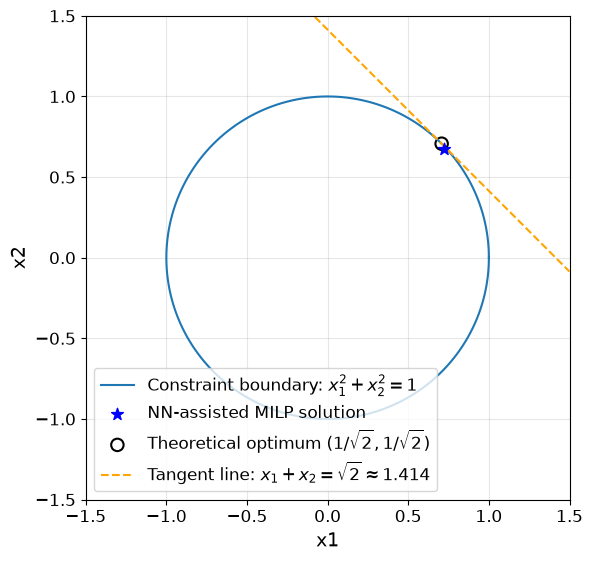

In [7]:
# --------------------------
# Step 7. Visualization
# --------------------------
try:
    import matplotlib.pyplot as plt

    # Unit circle boundary
    theta = np.linspace(0, 2*np.pi, 400)
    xs = np.cos(theta)
    ys = np.sin(theta)

    # Theoretical optimum and tangent line
    sqrt2 = float(np.sqrt(2.0))
    x_th = 1.0 / sqrt2
    theo_point = (x_th, x_th)  # (1/√2, 1/√2)
    # Tangent line: x1 + x2 = √2  => y = √2 - x
    grid = np.linspace(BOX_LB, BOX_UB, 400)
    y_line = sqrt2 - grid
    mask = (y_line >= BOX_LB) & (y_line <= BOX_UB)

    fig, ax = plt.subplots(figsize=(6, 6))

    # Plot constraint boundary
    ax.plot(xs, ys, label=r"Constraint boundary: $x_1^2 + x_2^2 = 1$", linewidth=1.5)

    # Plot NN-assisted MILP solution
    ax.scatter([x1_sol], [x2_sol], s=80, marker="*",
               color="blue", label="NN-assisted MILP solution", zorder=5)

    # Plot theoretical optimum (raw string for LaTeX math)
    ax.scatter([theo_point[0]], [theo_point[1]], s=80, marker="o",
               facecolors="none", edgecolors="k", linewidths=1.5,
               label=r"Theoretical optimum $(1/\sqrt{2}, 1/\sqrt{2})$")

    # Plot tangent line
    ax.plot(grid[mask], y_line[mask], linestyle="--", color="orange",
            linewidth=1.5, label=fr"Tangent line: $x_1 + x_2 = \sqrt{{2}} \approx {sqrt2:.3f}$")

    # Style and fonts
    ax.set_xlim(BOX_LB, BOX_UB)
    ax.set_ylim(BOX_LB, BOX_UB)
    ax.set_aspect("equal", "box")
    ax.grid(True, alpha=0.3)

    # Increase font sizes
    ax.set_xlabel("x1", fontsize=14)
    ax.set_ylabel("x2", fontsize=14)
    ax.tick_params(axis="both", labelsize=12)
    ax.legend(fontsize=12, loc="lower left")

    fig.tight_layout()
    plt.show()

except Exception as e:
    print("(Plot skipped) Matplotlib issue:", e)


## Step 8. Advanced Application in Power Systems

The example above demonstrates a basic workflow for NN-assisted optimization: approximate a nonlinear constraint with a shallow ReLU MLP and embed that trained network in a mixed-integer linear programming (MILP) model. Larger applications may use deeper networks, but the model used in this notebook has only one hidden layer.

In power systems, this idea is useful when security constraints are nonlinear, dynamic, or expensive to model directly. The two papers below apply this concept to virtual inertia scheduling (VIS), where inverter-based resources (IBRs) are scheduled to provide frequency support while satisfying economic and security requirements.

- [Virtual Inertia Scheduling (VIS) for Real-Time Economic Dispatch of IBR-Penetrated Power Systems](https://ieeexplore.ieee.org/abstract/document/10264213)
- [Virtual Inertia Scheduling (VIS) for Microgrids With Static and Dynamic Security Constraints](https://ieeexplore.ieee.org/document/10729702/)

As you read, focus on:

1. Which constraints are approximated or linearized?
2. How are feasibility and dynamic security verified?
